In [ ]:
"""
梯度下降法 是为了找到最小损失函数的方法
梯度：函数增长最快的地方就是梯度 方向是函数变换速度最快的方向
学习率：学习率过小 可能造成收敛速度慢增加损耗 学习率过大可能错过最佳值
计算公式：W新 = W旧 - 学习率 * 梯度

训练模型时的三个参数
epoch：所有样本每训练一次就是一个epoch
batch_size：每次选取N个样本训练一次就是一个batch_size 就是样本数量
literation：每次batch_size训练一次就是一个literation
1.梯度下降优化算法
可能会遇到的问题：坡度变缓 遇到鞍点 局部最小值
解决方法
1.1 指数加权平均
    根据权重不同 距离近的权重大 对指数加权平均的影响更大
1.2 动量法(Momentum): 只从 梯度的方向优化, 给1个动量因子(就是β).  解决 鞍点的情况
        公式:
            St = β * St-1 + (1 - β) * Gt        本次的加权历史平均梯度 = β * 上次的加权历史平均梯度 + (1 - β) * 本次的梯度
            W新 = W旧 - lr * St                  就是把之前的 Gt(本次梯度) 换成 St(本次的 加权历史平均梯度)

1.3 AdaGrad: 只从 学习率角度 优化, AdaGrad的学习率总体会逐渐减小.    解决 梯度下降过快的情况
        公式:
            小常数σ:       默认是1e-10, 作用是: 防止分母变为0
            累计平方梯度:   St = St-1 + Gt²
            优化后的学习率: lr新 = lr旧 / (√St + σ)
            最终:
                W新 = W旧 - lr新 * Gt
        问题:
            后期学习率缓慢, 易陷入局部最优, 部分参数更新激进, 可能还存在学习率过早, 过量的降低.
1.4 RMSProp: 只从 学习率角度 优化, RMSProp的学习率会逐渐减小. 可以理解为: RMS Prop是针对于AdaGrad的优化版.
        公式:
            小常数σ:              默认是1e-10, 作用是: 防止分母变为0
            指数加权累计平方梯度:   St = β * St-1 + (1 - β) * Gt²
            优化后的学习率:        lr新 = lr旧 / (√St + σ)
            最终:
                                W新 = W旧 - lr新 * Gt
        解释:
            RMS Propagation 通过引入 衰减系数β, 控制历史梯度 对 历史梯度信息获取的多少.

1.5 Adam: 自适应矩估计        从学习率 和 梯度两个角度优化.
        即: 修正梯度 和 学习率, 即: Adam = 动量法 + RMSProp

        公式:
            一阶矩估计: m_t = β1 * m_t-1 + (1 - β1) * Gt
            二阶矩估计: s_t = β2 * s_t-1 + (1 - β2) * Gt²
            偏差矫正后的估计:
                m_t^ = m_t / (1 - β1^t)
                s_t^ = s_t / (1 - β2^t)

            更新后的学习率:
                lr新 = lr旧 / (√s_t^ + σ)

            W新 = W旧 - lr新 * m_t^
        解释:
            需要传入2个β, β1 -> 更新梯度, β2 -> 更新累计平方梯度 -> 更新学习率.

总结:  如何选择梯度下降优化方法
    简单任务和较小的模型：     SGD 或 Momentum
    复杂任务或有大量数据：     Adam 是最常用的选择，因其在大部分任务上都表现优秀
    需要处理稀疏数据或文本数据：Adagrad 或 RMSProp
2.学习率选择
学习率的衰减方法：
    2.1 等间隔的衰减
    2.2 指定间隔的衰减
    2.3 按指数学习率衰减
"""

In [1]:
# 导包
import torch
import matplotlib.pyplot as plt
ELEMENT_NUMBER = 30


tensor([-11.2584, -11.5236,  -2.5058,  -4.3388,   8.4871,   6.9201,  -3.1601,
        -21.1522,   3.2227, -12.6333,   3.4998,   3.0813,   1.1984,  12.3766,
         -1.4347,  -1.1161,  -6.1358,   0.3159,  -4.9268,   2.4841,   4.3970,
          1.1241,  -8.4106, -23.1604,  -1.0231,   7.9244,  -2.8967,   0.5251,
          5.2286,  23.0221])


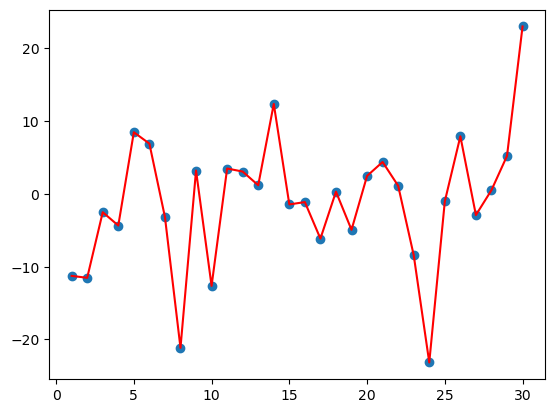

In [6]:
# 没有梯度优化的

# 固定随机数种子
torch.manual_seed(0)
# 产生30天的随机温度
temperature = torch.randn(size=[ELEMENT_NUMBER,]) * 10
print(temperature)
# 绘制平均温度
days = torch.arange(1, ELEMENT_NUMBER + 1, 1)
plt.plot(days, temperature, color='r')
plt.scatter(days, temperature)
plt.show()


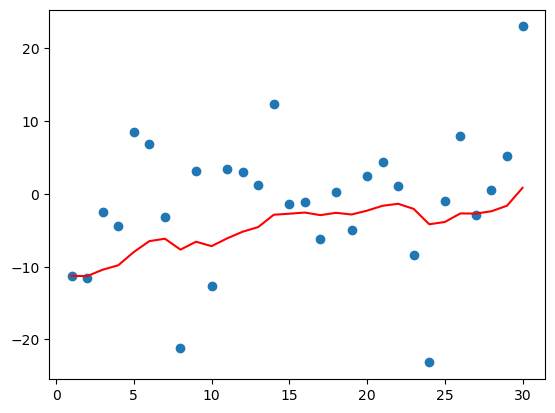

In [7]:
# 指数加权平均
beta = 0.9
torch.manual_seed(0) # 固定随机数种子
temperature = torch.randn(size=[ELEMENT_NUMBER,]) * 10 # 产生30天的随机温度
exp_weight_avg = []
for idx, temp in enumerate(temperature, 1):  # 从下标1开始
    # 第一个元素的的 EWA 值等于自身
    if idx == 1:
        exp_weight_avg.append(temp)
        continue
    # 第二个元素的 EWA 值等于上一个 EWA 乘以 β + 当前气温乘以 (1-β)
    new_temp = exp_weight_avg[idx - 2] * beta + (1 - beta) * temp
    exp_weight_avg.append(new_temp)
days = torch.arange(1, ELEMENT_NUMBER + 1, 1)
plt.plot(days, exp_weight_avg, color='r')
plt.scatter(days, temperature)
plt.show()


In [15]:

# 动量算法 Momenyum算法
# 初始化权重系数
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 实例化优化方法SGD指定参数beta=0.9 使用随机梯度下降
optimizer = torch.optim.SGD([w], lr=0.01, momentum=0.9)
# 定义更新次数
update = 10
# 第一次更新 计算梯度并对参数进行更新
for i in range(update):
    # 创建损失函数
    loss = ((w**2)/2).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"第{i+1}次更新后w的梯度：{w.grad.detach().numpy()} w的权重：{w.data.detach().numpy()}")

第1次更新后w的梯度：[1.] w的权重：[0.99]
第2次更新后w的梯度：[0.99] w的权重：[0.97110003]
第3次更新后w的梯度：[0.97110003] w的权重：[0.94437903]
第4次更新后w的梯度：[0.94437903] w的权重：[0.91088635]
第5次更新后w的梯度：[0.91088635] w的权重：[0.87163407]
第6次更新后w的梯度：[0.87163407] w的权重：[0.82759064]
第7次更新后w的梯度：[0.82759064] w的权重：[0.77967566]
第8次更新后w的梯度：[0.77967566] w的权重：[0.7287555]
第9次更新后w的梯度：[0.7287555] w的权重：[0.67563975]
第10次更新后w的梯度：[0.67563975] w的权重：[0.6210792]


In [19]:
# AdaGrad算法 针对学习率  发现梯度的下降速度明显变慢了
# 初始化权重系数
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 实例化优化方法SGD指定参数beta=0.9 使用随机梯度下降
optimizer = torch.optim.Adagrad([w], lr=0.01)
# 定义更新次数
update = 10
# 第一次更新 计算梯度并对参数进行更新
for i in range(update):
    # 创建损失函数
    loss = ((w**2)/2).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"第{i+1}次更新后w的梯度：{w.grad.detach().numpy()} w的权重：{w.data.detach().numpy()}")

第1次更新后w的梯度：[1.] w的权重：[0.99]
第2次更新后w的梯度：[0.99] w的权重：[0.9829646]
第3次更新后w的梯度：[0.9829646] w的权重：[0.97723794]
第4次更新后w的梯度：[0.97723794] w的权重：[0.97229034]
第5次更新后w的梯度：[0.97229034] w的权重：[0.9678739]
第6次更新后w的梯度：[0.9678739] w的权重：[0.96384925]
第7次更新后w的梯度：[0.96384925] w的权重：[0.960129]
第8次更新后w的梯度：[0.960129] w的权重：[0.9566541]
第9次更新后w的梯度：[0.9566541] w的权重：[0.9533823]
第10次更新后w的梯度：[0.9533823] w的权重：[0.95028234]


In [ ]:
# RMSProp算法是对AdaGrad算法的优化 学习率是缓慢变小 
# 初始化权重系数
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 实例化优化方法RMSprop优化器
optimizer = torch.optim.RMSprop([w], lr=0.01, alpha=0.9)
# 定义更新次数
update = 10
# 第一次更新 计算梯度并对参数进行更新
for i in range(update):
    # 创建损失函数
    loss = ((w**2)/2).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # 参数：最后一个是区第0组对应的学习率
    print(f"第{i+1}次更新后w的梯度：{w.grad.detach().numpy()} w的权重：{w.data.detach().numpy()} 学习率：{optimizer.param_groups[0]['lr']}")

第1次更新后w的梯度：[1.] w的权重：[0.96837723] 学习率：0.01
第2次更新后w的梯度：[0.96837723] w的权重：[0.945788] 学习率：0.01
第3次更新后w的梯度：[0.945788] w的权重：[0.9270531] 学习率：0.01
第4次更新后w的梯度：[0.9270531] w的权重：[0.91054344] 学习率：0.01
第5次更新后w的梯度：[0.91054344] w的权重：[0.8955067] 学习率：0.01
第6次更新后w的梯度：[0.8955067] w的权重：[0.8815248] 学习率：0.01
第7次更新后w的梯度：[0.8815248] w的权重：[0.8683383] 学习率：0.01
第8次更新后w的梯度：[0.8683383] w的权重：[0.85577357] 学习率：0.01
第9次更新后w的梯度：[0.85577357] w的权重：[0.8437082] 学习率：0.01
第10次更新后w的梯度：[0.8437082] w的权重：[0.83205235] 学习率：0.01


In [26]:
# Adma优化梯度下降算法 结合了动量算法和RMSProp 更优秀
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 实例化优化方法RMSprop优化器   
# 参数三是超参数 一阶二阶矩的系数
optimizer = torch.optim.Adam([w], lr=0.1, betas=[0.9,0.9])
# 定义更新次数
update = 10
# 第一次更新 计算梯度并对参数进行更新
for i in range(update):
    # 创建损失函数
    loss = ((w**2)/2).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # 参数：最后一个是区第0组对应的学习率
    print(f"第{i+1}次更新后w的梯度：{w.grad.detach().numpy()} w的权重：{w.data.detach().numpy()} 学习率：{optimizer.param_groups[0]['lr']}")

第1次更新后w的梯度：[1.] w的权重：[0.9] 学习率：0.1
第2次更新后w的梯度：[0.9] w的权重：[0.80013853] 学习率：0.1
第3次更新后w的梯度：[0.80013853] w的权重：[0.70055103] 学习率：0.1
第4次更新后w的梯度：[0.70055103] w的权重：[0.60141987] 学习率：0.1
第5次更新后w的梯度：[0.60141987] w的权重：[0.50299245] 学习率：0.1
第6次更新后w的梯度：[0.50299245] w的权重：[0.40560555] 学习率：0.1
第7次更新后w的梯度：[0.40560555] w的权重：[0.30971828] 学习率：0.1
第8次更新后w的梯度：[0.30971828] w的权重：[0.215955] 学习率：0.1
第9次更新后w的梯度：[0.215955] w的权重：[0.12515694] 学习率：0.1
第10次更新后w的梯度：[0.12515694] w的权重：[0.038435] 学习率：0.1


In [ ]:
"""
案例:
    演示 学习率衰减优化方式 -> 即: 可以理解为 我们在手动调整 学习率.

背景:
    之前学的AdaGrad, RMSProp, Adam这些梯度下降优化方式, 都可以修改 学习率, 但是底层无法人为精准控制, 例如: 多少轮更新一次, 制定轮更新一次等...
    针对于这种情况, PyTorch中加入了 学习率衰减优化方式, 可以人为的控制学习率的变化.

方式:
    1.等间隔学习率优化.
        间隔指定的轮数, 优化(更新)学习率.
        lr新 = lr旧 * gamma

    2. 指定间隔学习率优化.
        设置指定的轮数, 当达到指定的轮数后, 即可 自动优化 学习率
        lr新 = lr旧 * gamma

    3.指数学习率优化.
        lr新 = lr旧 * gamma^epoch

总结:
    1. 等间隔学习率衰减.
        固定步长衰减, 简单易实现.
        适用于: 大型数据集, 较为简单的任务.
        优点: 直观, 易于调试.
        缺点: 学习率变化较大, 可能跳过最优点.
    2. 指定间隔学习率衰减.
        指定步长衰减, 相对简单, 容易调整.
        适用于: 对训练平稳性要求较高的任务.
        优点: 易于调试, 稳定训练过程.
        缺点: 在某些情况下可能衰减过快, 导致优化提前停滞.
    3. 指数间隔学习率衰减.
        平滑指数衰减, 历史平均考虑.  需要额外历史计算, 较复杂.
        适用于: 高精度训练, 避免过快收敛.
        优点: 平滑且考虑历史更新, 收敛稳定性较强.
        缺点: 超参数调节较为复杂, 可能需要更多的计算资源.
"""

In [ ]:
# 导包
from torch import optim

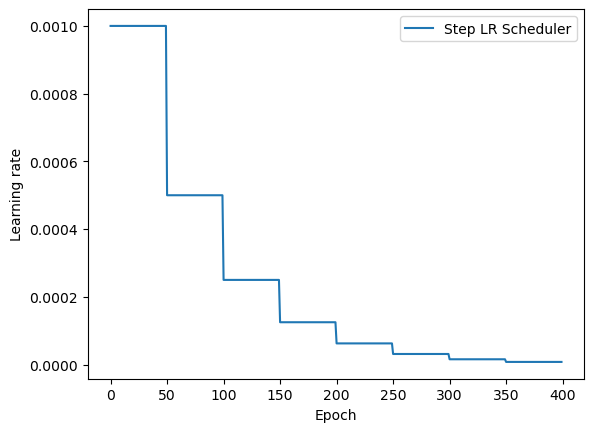

In [ ]:

# 等间隔的学习率衰减
# 参数初始化
LR = 0.1            # 学习率初始为0.1
iteration = 10             # 迭代的次数为10
max_epoch = 400            # 最大的循环次数为200
# 设定的最终目标 就是让梯度减为零
y_true = torch.tensor([0])
x = torch.tensor([1.0])
w = torch.tensor([1.0], requires_grad=True)
# 优化器
optimizer = optim.SGD([w],momentum=0.9)
# 设置学习下降策略 等间隔的衰减
    # 参数二三分别为 调整轮次和调整系数
scheduler_lr = optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)
# 获取学习率的值和当前的轮次
lr_list, epoch_list = list(), list()
# 训练模型得到lr和epoch值
for epoch in range(max_epoch):
    lr_list.append(scheduler_lr.get_last_lr())          # 获取当前的lr
    epoch_list.append(epoch)            # 获取当前的epoch
    for i in range(iteration):          # 遍历每一个批次的样本
        y_pred = w*x
        # 构建损失函数
        loss = (y_pred - y_true).pow(2).sum()
        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 更细梯度
        optimizer.step()
    # 更新下一个epoch学习率 达到指定的样本之后更新学习率
    scheduler_lr.step()
plt.plot(epoch_list, lr_list, label="Step LR Scheduler")
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.legend()
plt.show()



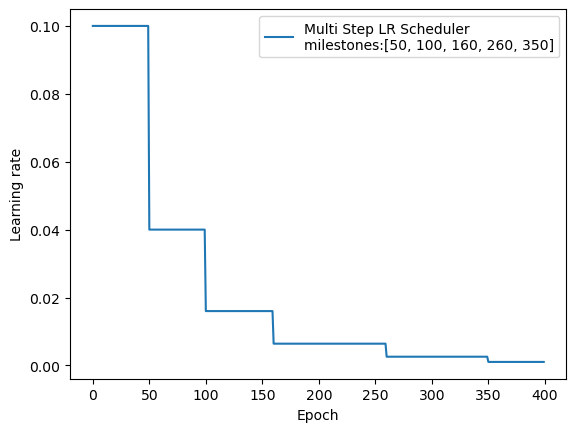

In [23]:
# 指定间隔的学习率衰减
torch.manual_seed(1)
LR = 0.1
iteration = 10
max_epoch = 400
# 定义权重和目标值
weights = torch.randn((1),requires_grad=True)
traget = torch.zeros((1))
# 定义优化器
optimizer = optim.SGD([weights],lr=LR,momentum=0.9)
# 设置要变化的间隔点
milestones = [50, 100, 160, 260, 350]
# 创建衰减函数
scheduler_lr = optim.lr_scheduler.MultiStepLR(optimizer,milestones=milestones,gamma=0.4)
# 获取学习率的值和当前的轮次
lr_list, epoch_list = list(), list()
# 训练模型得到lr和epoch值
for epoch in range(max_epoch):
    lr_list.append(scheduler_lr.get_last_lr())          # 获取当前的lr
    epoch_list.append(epoch)            # 获取当前的epoch
    for i in range(iteration):          # 遍历每一个批次
        # 构建损失函数 使用sum()函数 是为了确保最后的值是一个能求导的张量
        loss = (weights-traget).pow(2).sum()
        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 更细梯度
        optimizer.step()
    # 更新下一个epoch学习率
    scheduler_lr.step()
plt.plot(epoch_list, lr_list, label="Multi Step LR Scheduler\nmilestones:{}".format(milestones))
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.legend()
plt.show()


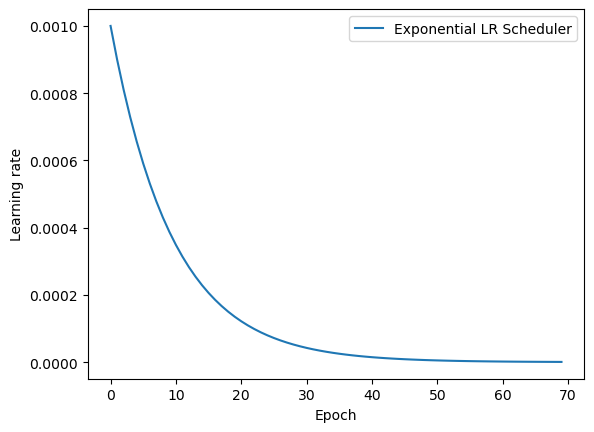

In [ ]:
# 按指数学习率进行衰减
# 参数初始化
LR = 0.1            # 学习率初始为0.1
iteration = 10             # 迭代的次数为10
max_epoch = 70             # 最大的循环次数为200
y_true = torch.tensor([0])
x = torch.tensor([1.0])
w = torch.tensor([1.0], requires_grad=True)
# 优化器
optimizer = optim.SGD([w],momentum=0.9)
# 设置学习下降策略 等间隔的衰减
scheduler_lr = optim.lr_scheduler.ExponentialLR(optimizer,gamma=0.9)
# 获取学习率的值和当前的轮次
lr_list, epoch_list = list(), list()
# 训练模型得到lr和epoch值
for epoch in range(max_epoch):
    lr_list.append(scheduler_lr.get_last_lr())          # 获取当前的lr
    epoch_list.append(epoch)            # 获取当前的epoch
    for i in range(iteration):          # 遍历每一个批次
        # 构建损失函数
        loss = ((w*x-y_true)**2)/2.0
        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 更细梯度
        optimizer.step()
    # 更新下一个epoch学习率
    scheduler_lr.step()
plt.plot(epoch_list, lr_list, label="Exponential LR Scheduler")
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.legend()
plt.show()

